# Multiple return values and streaming generators

One task returns two separate ObjectRefs (num_returns=2); another is a generator whose values stream back one by one (num_returns="streaming").

**When to use it.** Split outputs that downstream steps consume separately, or long-running producers whose partial results you want before the task finishes.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

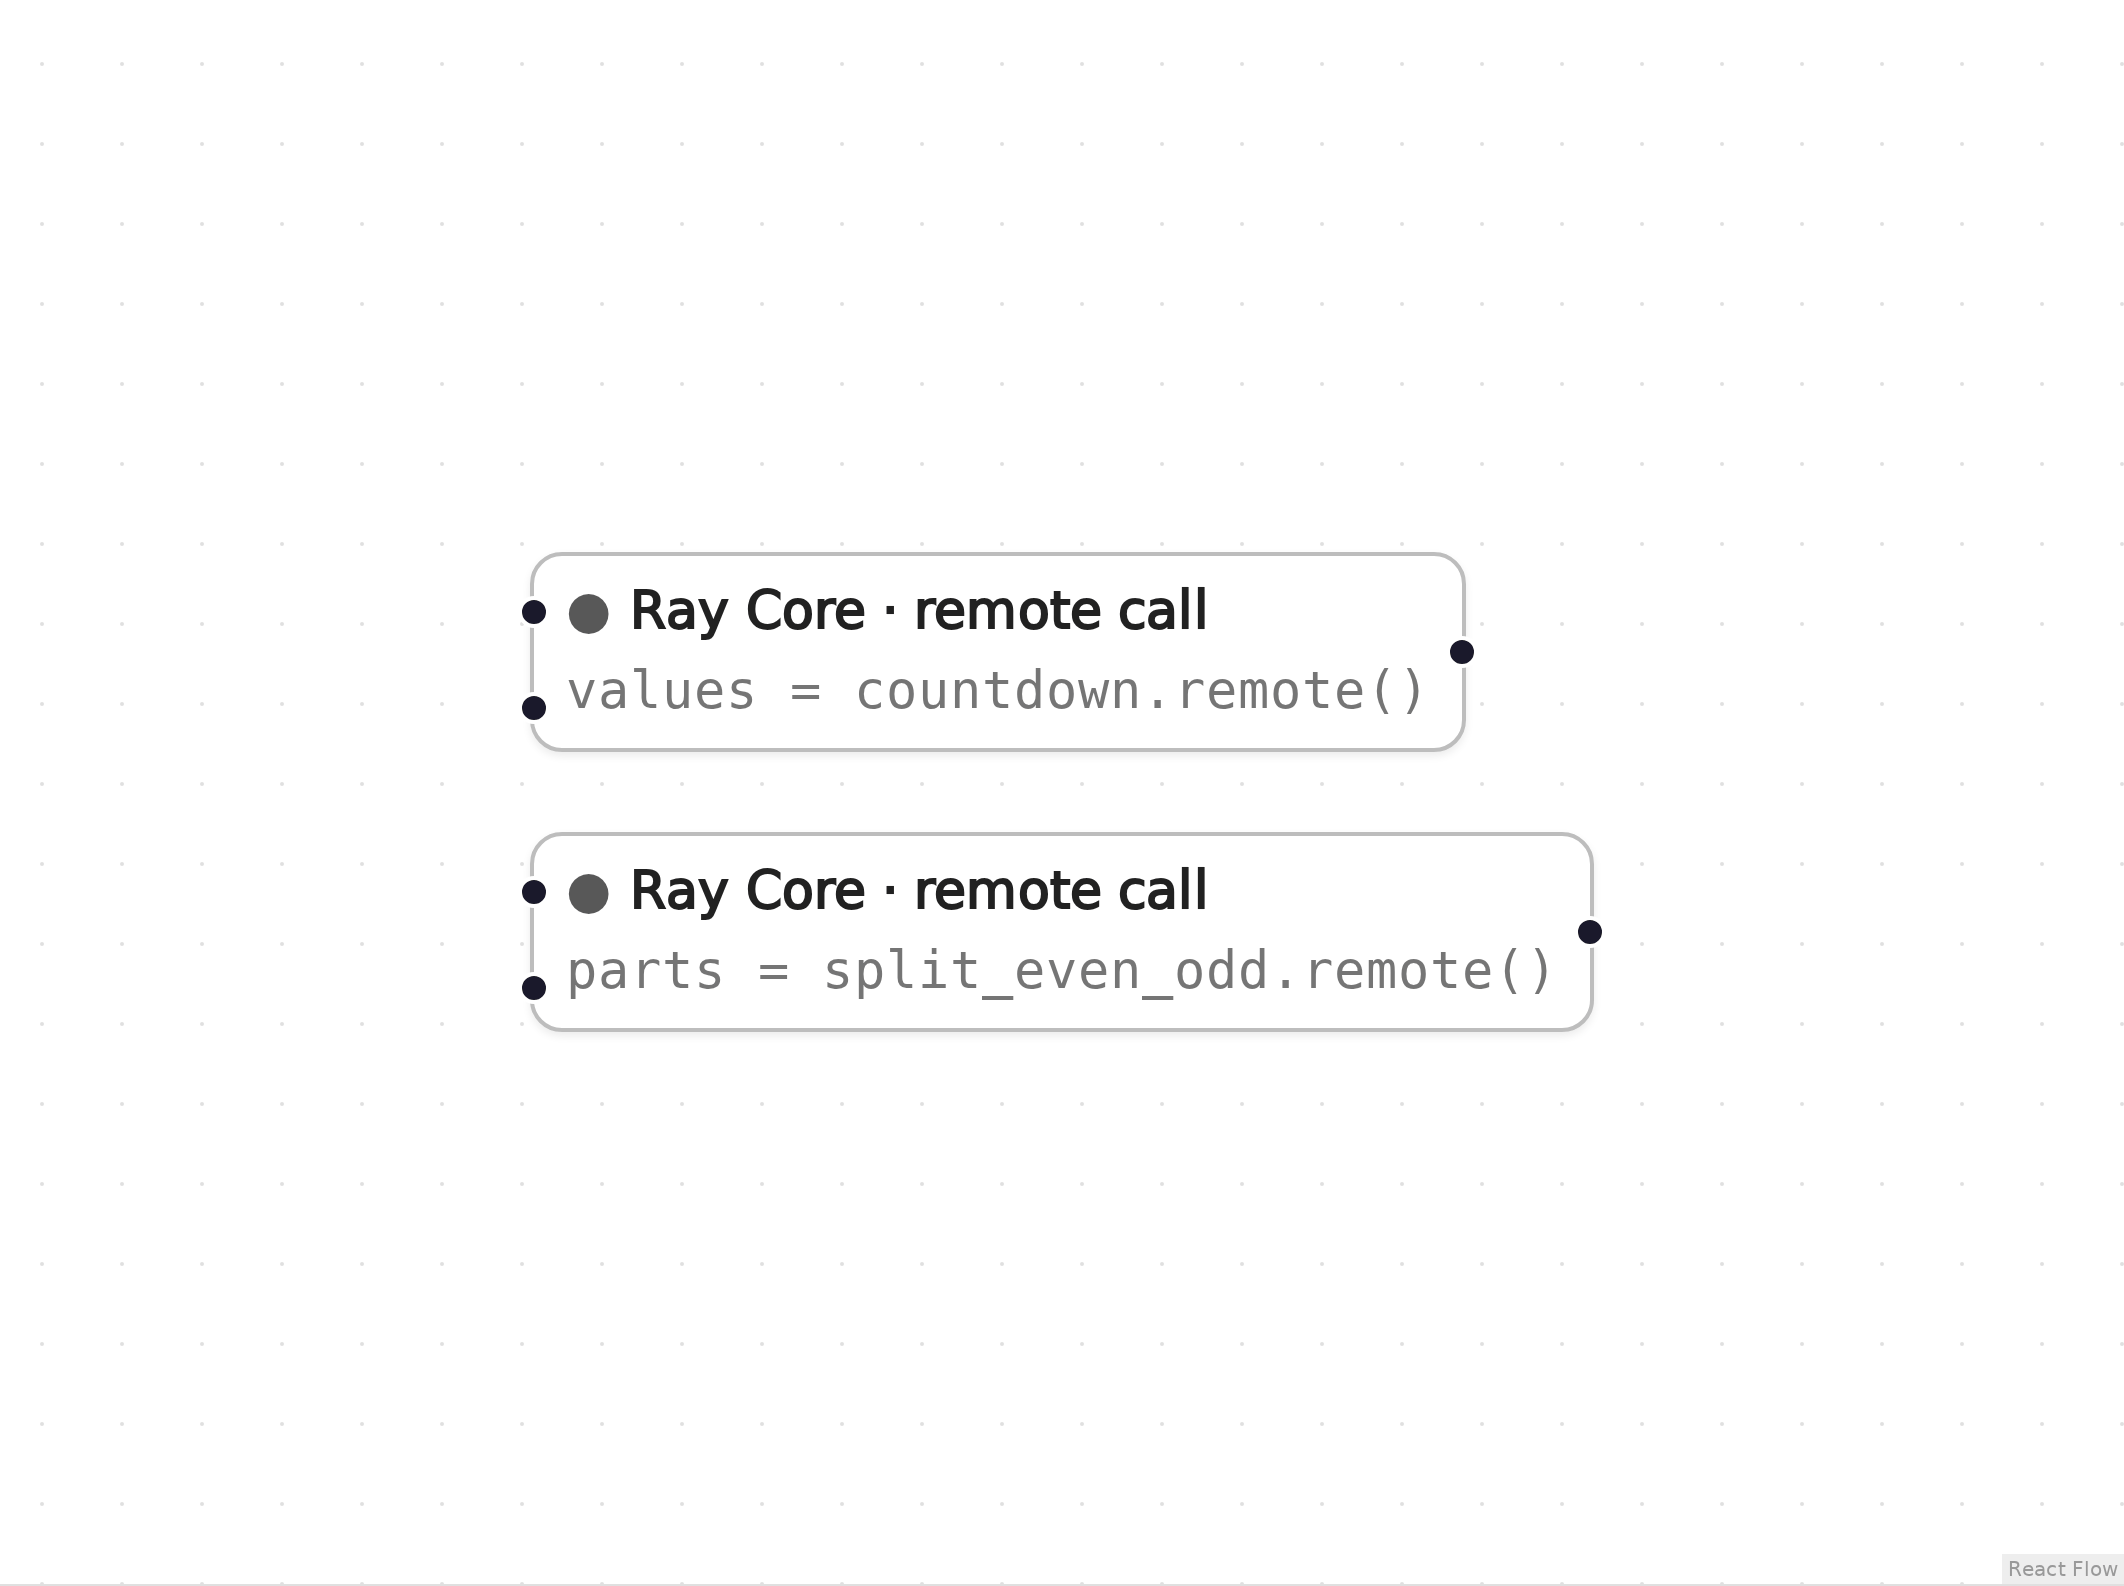

*The graph in Eugo's visual Ray builder.* The canvas does not draw the return options: `split_even_odd` is set to `num_returns=2` and `countdown` to `num_returns="streaming"` in each node's options, as the generated code below shows.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
def split_even_odd(values):
    evens = [v for v in values if v % 2 == 0]
    odds = [v for v in values if v % 2 == 1]
    return evens, odds  # num_returns=2: each element becomes its own ObjectRef


def countdown(n):
    for i in range(n, 0, -1):
        yield i  # num_returns="streaming": each yield is sent back as soon as it exists

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

_n1 = ray.remote(split_even_odd).options(num_returns=2).remote([1, 2, 3, 4, 5, 6])
parts = ray.get(_n1)
_n2 = ray.remote(countdown).options(num_returns="streaming").remote(5)
values = [ray.get(_ref) for _ref in _n2]

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert parts == [[2, 4, 6], [1, 3, 5]], parts
assert values == [5, 4, 3, 2, 1], values
print("parts =", parts)
print("values =", values)

parts = [[2, 4, 6], [1, 3, 5]]
values = [5, 4, 3, 2, 1]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote task** (node `n1`, lines 8–9)

```python
_n1 = ray.remote(split_even_odd).options(num_returns=2).remote([1, 2, 3, 4, 5, 6])
parts = ray.get(_n1)
```

num_returns=2 makes the call return two ObjectRefs, one per tuple element; ray.get on the pair returns both lists.

**Remote task** (node `n2`, lines 10–11)

```python
_n2 = ray.remote(countdown).options(num_returns="streaming").remote(5)
values = [ray.get(_ref) for _ref in _n2]
```

num_returns="streaming" returns an ObjectRefGenerator. Iterating it yields a ref per yield as the task produces them.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()